In [2]:
from matminer.datasets import load_dataset , get_available_datasets
import pandas as pd

# df = load_dataset("matbench_mp_gap")
df = pd.read_csv("matbench_mp_gap.csv") #All pymatgen Structures DS changed to strings - had to fix it
print(df.head())
# df.to_csv("matbench_mp_gap.csv", index=False)

                                           structure  gap pbe
0  Full Formula (K4 Mn4 O8)\nReduced Formula: KMn...   1.3322
1  Full Formula (Cr3 Ni1)\nReduced Formula: Cr3Ni...   0.0000
2  Full Formula (Cs1 Rb1 As1)\nReduced Formula: C...   0.0000
3  Full Formula (Si1 Sn1)\nReduced Formula: SiSn\...   0.4113
4  Full Formula (Ca3 P2)\nReduced Formula: Ca3P2\...   0.3514


In [4]:
print(df['structure'][0])
print(df['gap pbe'][0])

Full Formula (K4 Mn4 O8)
Reduced Formula: KMnO2
abc   :   6.406364   6.406467   7.044309
angles: 117.047604 117.052641  89.998496
pbc   :       True       True       True
Sites (16)
  #  SP           a         b         c    magmom
---  ----  --------  --------  --------  --------
  0  K     0.000888  0.002582  0.005358    -0.005
  1  K     0.504645  0.002727  0.005671    -0.005
  2  K     0.496497  0.498521  0.493328    -0.005
  3  K     0.496657  0.994989  0.493552    -0.005
  4  Mn    0.993288  0.493319  0.986797     4.039
  5  Mn    0.005896  0.005967  0.512019     4.039
  6  Mn    0.005704  0.505997  0.511635     4.039
  7  Mn    0.493721  0.493503  0.987141     4.039
  8  O     0.190852  0.749673  0.49925     -0.097
  9  O     0.74987   0.691083  0.999719    -0.097
 10  O     0.750076  0.308682  0.000128    -0.097
 11  O     0.807914  0.749345  0.498618    -0.097
 12  O     0.241545  0.298978  0.98309     -0.073
 13  O     0.815297  0.257926  0.515695    -0.073
 14  O     0.20002

In [5]:
print(df.isnull().sum())
df["gap pbe"].describe()

structure    0
gap pbe      0
dtype: int64


count    106113.000000
mean          1.214627
std           1.598966
min           0.000000
25%           0.000000
50%           0.273800
75%           2.207500
max           9.721200
Name: gap pbe, dtype: float64

In [17]:
print(type(df["structure"].iloc[0]))
print(df["structure"].iloc[0][:500])

<class 'str'>
Full Formula (K4 Mn4 O8)
Reduced Formula: KMnO2
abc   :   6.406364   6.406467   7.044309
angles: 117.047604 117.052641  89.998496
pbc   :       True       True       True
Sites (16)
  #  SP           a         b         c    magmom
---  ----  --------  --------  --------  --------
  0  K     0.000888  0.002582  0.005358    -0.005
  1  K     0.504645  0.002727  0.005671    -0.005
  2  K     0.496497  0.498521  0.493328    -0.005
  3  K     0.496657  0.994989  0.493552    -0.005
  4  Mn    0.99328


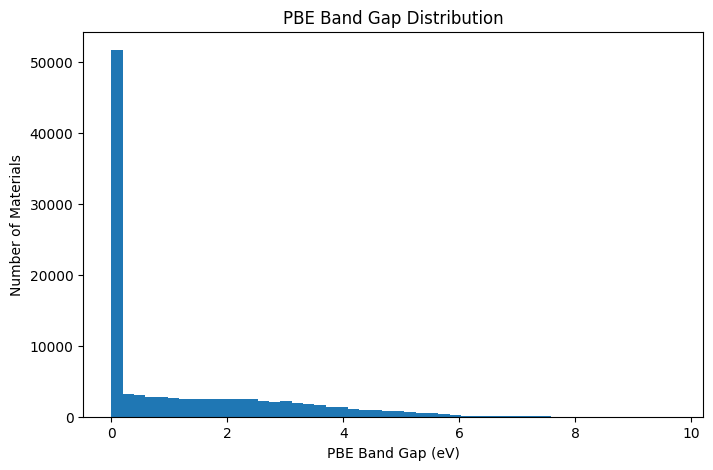

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    df["gap pbe"],
    bins=50
)

plt.ylabel("Number of Materials")
plt.xlabel("PBE Band Gap (eV)")
plt.title("PBE Band Gap Distribution")

plt.show()

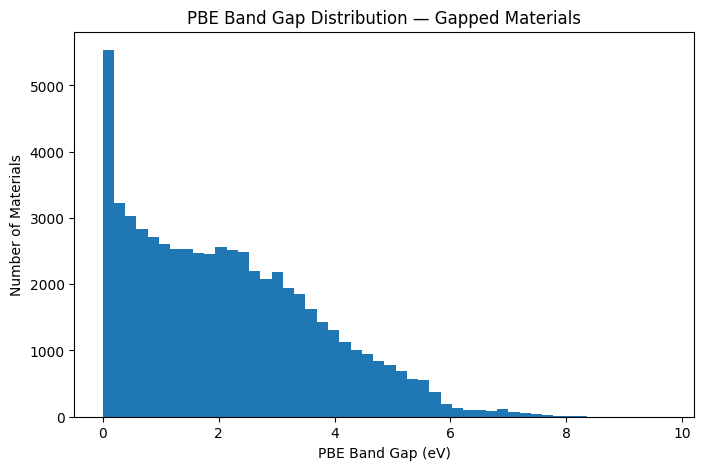

In [8]:
gapped = df[df["gap pbe"] > 0]

plt.figure(figsize=(8,5))

plt.hist(
    gapped["gap pbe"],
    bins=50
)

plt.xlabel("PBE Band Gap (eV)")
plt.ylabel("Number of Materials")
plt.title("PBE Band Gap Distribution — Gapped Materials")

plt.show()

In [15]:
zero_gap = (df["gap pbe"] == 0).sum()
total = len(df)

print("Zero band-gap materials:", zero_gap)
print("Total materials:", total)
print("Percentage:", zero_gap / total * 100)

Zero band-gap materials: 46151
Total materials: 106113
Percentage: 43.49231479649053


In [16]:
df["num_atoms"] = df["structure"].apply(len)

print(df["num_atoms"].describe())

df["num_elements"] = df["structure"].apply(
    lambda s: len(set(str(site.specie) for site in s))
)

print(df["num_elements"].describe())

count    106113.000000
mean       1769.814085
std        1499.472206
min         246.000000
25%         785.000000
50%        1312.000000
75%        2258.000000
max       22505.000000
Name: num_atoms, dtype: float64


AttributeError: 'str' object has no attribute 'specie'

In [13]:
import torch
from torch_geometric.data import Data
from pymatgen.core import Structure


def structure_to_graph(structure, band_gap, cutoff=5.0):

    x = []

    for site in structure:

        Z = site.specie.Z

        # For now: atomic number as the node feature
        x.append([Z])

    x = torch.tensor(x, dtype=torch.float)

    neighbors = structure.get_all_neighbors(
        cutoff,
        include_index=True
    )

    edge_index = []
    edge_attr = []

    for i, site_neighbors in enumerate(neighbors):

        for neighbor in site_neighbors:

            j = neighbor.index
            distance = neighbor.nn_distance

            # i → j
            edge_index.append([i, j])

            # distance between atoms
            edge_attr.append([distance])


    edge_index = torch.tensor(
        edge_index,
        dtype=torch.long
    ).t().contiguous()

    edge_attr = torch.tensor(
        edge_attr,
        dtype=torch.float
    )

    y = torch.tensor(
        [band_gap],
        dtype=torch.float
    )

    data = Data(
        x=x,
        edge_index=edge_index,
        edge_attr=edge_attr,
        y=y
    )

    return data

In [14]:
structure = gapped['structure'][0]

data = structure_to_graph(
    structure,
    band_gap=1.3322,
    cutoff=5.0
)


AttributeError: 'str' object has no attribute 'specie'

In [10]:
dataset = []

for i in range(len(gapped)):

    structure = gapped.iloc[i]["structure"]
    band_gap = gapped.iloc[i]["gap pbe"]

    graph = structure_to_graph(
        structure=structure,
        band_gap=band_gap,
        cutoff=5.0
    )

    dataset.append(graph)

torch.save(dataset, "matbench_graphs_graphed_data.pt")

In [3]:
from torch_geometric.loader import DataLoader

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

# Soon to be completed

C:\Users\Navin Kumar\PyCharmMiscProject\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NameError: name 'dataset' is not defined